In [1]:
import os, re, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, MaxAbsScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from xgboost import XGBClassifier

SEED = 42
for folder in ['models', 'figures', 'results']:
    os.makedirs(folder, exist_ok=True)
order = ['negative', 'neutral', 'positive']
colors = {'negative': '#d1495b', 'neutral': '#edae49', 'positive': '#2e8b57'}

In [2]:
def save_show(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [3]:
df = pd.read_csv('nepal_tourism_reviews.csv')
print("Dataset shape:", df.shape)
df.info()

descriptions = {
    'city': 'City (Kathmandu or Pokhara)', 'domain': 'Type of place (Attraction or Hotel)',
    'place': 'Name of hotel/attraction', 'rating': 'Star rating 1-5',
    'label': 'Sentiment class (TARGET)', 'review': 'Review text (main INPUT)',
    'llama_label': 'Sentiment predicted by LLaMA', 'qwen_label': 'Sentiment predicted by Qwen',
}
data_table = pd.DataFrame({
    'Column': df.columns, 'Type': df.dtypes.astype(str).values,
    'Non-null': df.notnull().sum().values, 'Unique': df.nunique().values,
    'Description': [descriptions.get(c, 'LLM probability column') for c in df.columns]})
print("\n", data_table.to_string(index=False))
print("\nMissing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum(), "| duplicate review texts:", df['review'].duplicated().sum())
print("Empty reviews:", (df['review'].str.strip() == '').sum())

print("\nRating vs label:\n", pd.crosstab(df['rating'], df['label']))
print("Rating and the LLaMA/Qwen columns must NOT be inputs (leakage).")

Dataset shape: (10536, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10536 entries, 0 to 10535
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   city         10536 non-null  str    
 1   domain       10536 non-null  str    
 2   place        10536 non-null  str    
 3   rating       10536 non-null  int64  
 4   label        10536 non-null  str    
 5   review       10536 non-null  str    
 6   llama_label  10536 non-null  str    
 7   llama_p_neg  10536 non-null  float64
 8   llama_p_neu  10536 non-null  float64
 9   llama_p_pos  10536 non-null  float64
 10  qwen_label   10536 non-null  str    
 11  qwen_p_neg   10536 non-null  float64
 12  qwen_p_neu   10536 non-null  float64
 13  qwen_p_pos   10536 non-null  float64
dtypes: float64(6), int64(1), str(7)
memory usage: 5.6 MB

      Column    Type  Non-null  Unique                         Description
       city     str     10536       2         City (Kathmandu or Pokh

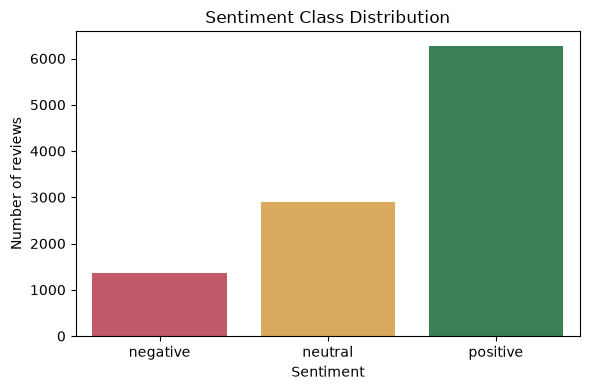

Insight: positive=59.5%, neutral=27.5%, negative=12.9%.
Always predicting 'positive' would already give high accuracy -> use macro F1 + class weights.


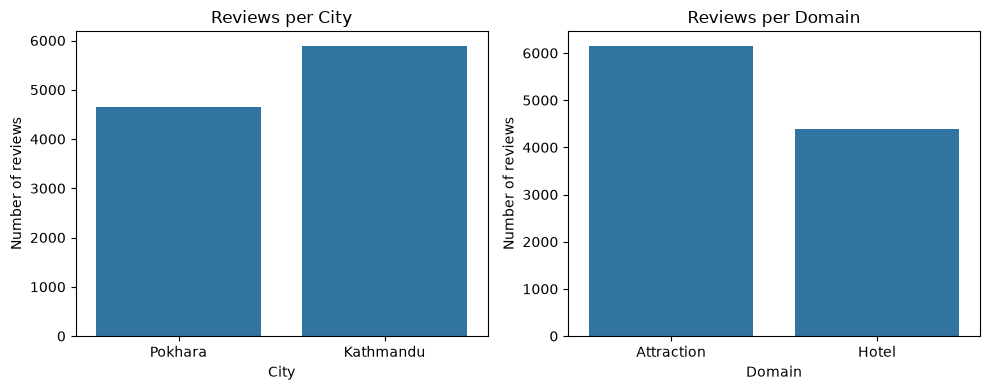

Reviews per city: {'Kathmandu': 5892, 'Pokhara': 4644} | per domain: {'Attraction': 6152, 'Hotel': 4384}


In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', order=order, hue='label', palette=colors, legend=False)
plt.title("Sentiment Class Distribution"); plt.xlabel("Sentiment"); plt.ylabel("Number of reviews")
save_show('class_distribution')
share = (df['label'].value_counts(normalize=True) * 100).round(1)
print(f"Insight: positive={share['positive']}%, neutral={share['neutral']}%, negative={share['negative']}%.")
print("Always predicting 'positive' would already give high accuracy -> use macro F1 + class weights.")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ['city', 'domain']):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Reviews per {col.capitalize()}"); ax.set_xlabel(col.capitalize()); ax.set_ylabel("Number of reviews")
save_show('city_domain')
print("Reviews per city:", df['city'].value_counts().to_dict(), "| per domain:", df['domain'].value_counts().to_dict())

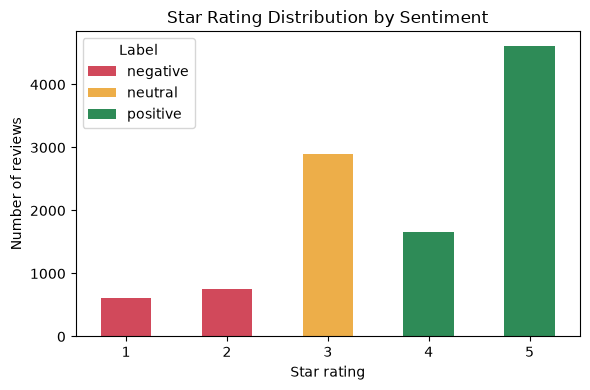

Insight: most reviews are 4-5 stars; each rating has one colour -> labels come from ratings.


In [5]:
pd.crosstab(df['rating'], df['label'])[order].plot(kind='bar', stacked=True, color=[colors[c] for c in order], figsize=(6, 4))
plt.title("Star Rating Distribution by Sentiment"); plt.xlabel("Star rating"); plt.ylabel("Number of reviews")
plt.xticks(rotation=0); plt.legend(title='Label')
save_show('rating_distribution')
print("Insight: most reviews are 4-5 stars; each rating has one colour -> labels come from ratings.")

count    10536.0
mean        69.4
std         68.3
min          8.0
25%         31.0
50%         47.0
75%         81.0
max       1302.0
Name: word_count, dtype: float64


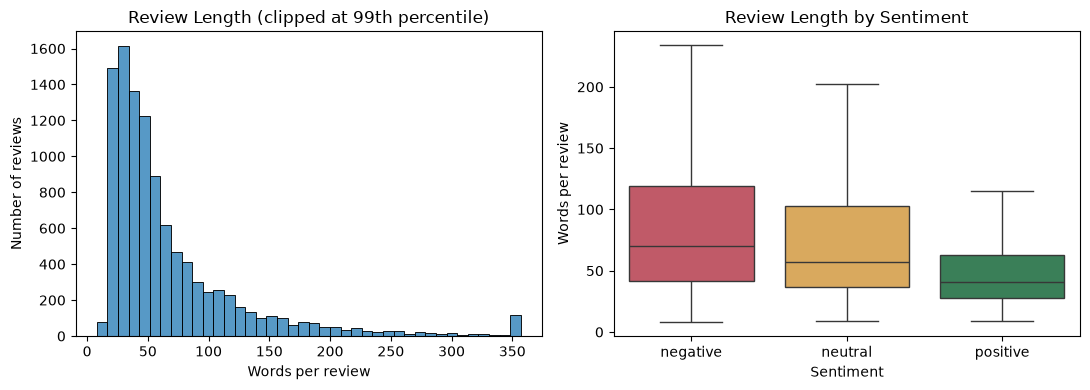

Median words per class: {'negative': 73.0, 'neutral': 58.0, 'positive': 41.0}


In [6]:
df['word_count'] = df['review'].str.split().str.len()
print(df['word_count'].describe().round(1))
limit = df['word_count'].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['word_count'].clip(upper=limit), bins=40, ax=axes[0])
axes[0].set_title("Review Length (clipped at 99th percentile)"); axes[0].set_xlabel("Words per review"); axes[0].set_ylabel("Number of reviews")
sns.boxplot(data=df[df['word_count'] <= limit], x='label', y='word_count', order=order, hue='label', palette=colors, legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Review Length by Sentiment"); axes[1].set_xlabel("Sentiment"); axes[1].set_ylabel("Words per review")
save_show('review_length')
print("Median words per class:", df.groupby('label')['word_count'].median().to_dict())

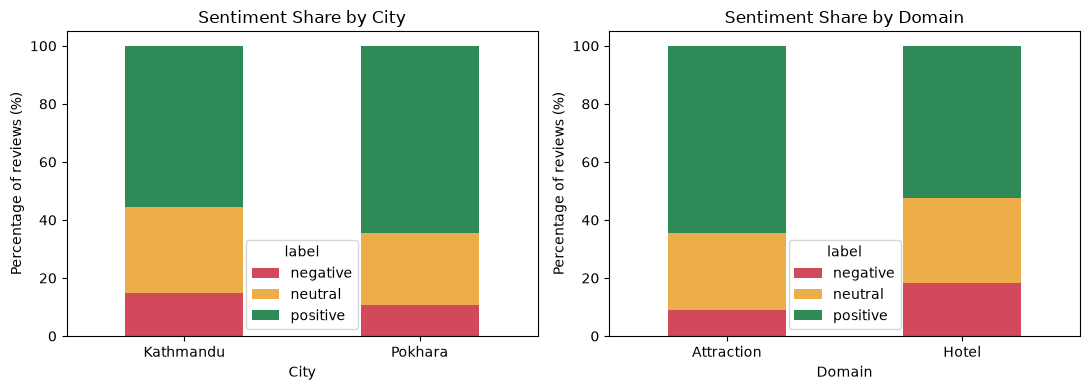

Positive share by city  : {'Kathmandu': 55.6, 'Pokhara': 64.6}
Positive share by domain: {'Attraction': 64.5, 'Hotel': 52.6}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['city', 'domain']):
    (pd.crosstab(df[col], df['label'], normalize='index')[order] * 100).plot(
        kind='bar', stacked=True, color=[colors[c] for c in order], ax=ax)
    ax.set_title(f"Sentiment Share by {col.capitalize()}"); ax.set_xlabel(col.capitalize())
    ax.set_ylabel("Percentage of reviews (%)"); ax.tick_params(axis='x', rotation=0)
save_show('sentiment_by_city_domain')
print("Positive share by city  :", (pd.crosstab(df['city'], df['label'], normalize='index')['positive'] * 100).round(1).to_dict())
print("Positive share by domain:", (pd.crosstab(df['domain'], df['label'], normalize='index')['positive'] * 100).round(1).to_dict())

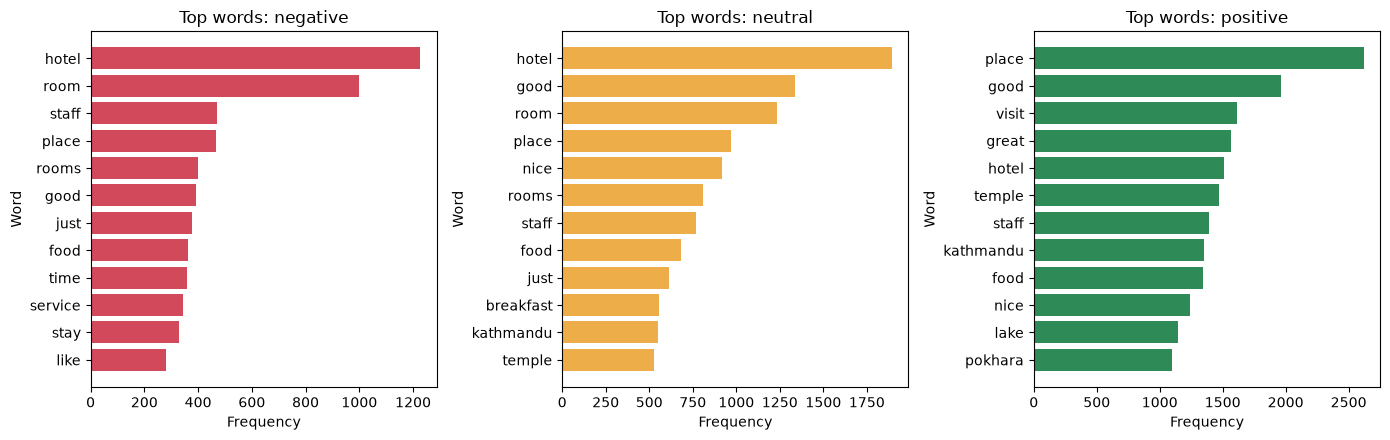

Insight: frequent words are descriptive and shared between classes -> TF-IDF with bigrams is used.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, label in zip(axes, order):
    cv = CountVectorizer(stop_words='english', min_df=5)
    counts = cv.fit_transform(df[df['label'] == label]['review'].str.lower())
    freq = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).nlargest(12)
    ax.barh(freq.index[::-1], freq.values[::-1], color=colors[label])
    ax.set_title("Top words: " + label); ax.set_xlabel("Frequency"); ax.set_ylabel("Word")
save_show('top_words')
print("Insight: frequent words are descriptive and shared between classes -> TF-IDF with bigrams is used.")

In [9]:
def clean_text(text):
    text = str(text).lower().replace("’", "'")
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = text.replace("can't", "can not").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)
    return re.sub(r'\s+', ' ', text).strip()

rows_before = len(df)
df = df.dropna(subset=['review', 'label'])
df = df[df['review'].str.strip() != ''].drop_duplicates().copy()
df['review_clean'] = df['review'].apply(clean_text)
print(f"\nRows before: {rows_before} | after cleaning: {len(df)}")
print(df[['review', 'review_clean']].head(3).to_string())


Rows before: 10536 | after cleaning: 10536
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                review                                                                                                                                                                                                                                                                                                                                                                                                                                                                     review_clean
0  We visited Devi's

In [10]:
FORBIDDEN = ['rating', 'llama_label', 'llama_p_neg', 'llama_p_neu', 'llama_p_pos',
             'qwen_label', 'qwen_p_neg', 'qwen_p_neu', 'qwen_p_pos']
X = df[['review_clean', 'city', 'domain']]
le = LabelEncoder()
y = le.fit_transform(df['label'])
assert not set(FORBIDDEN) & set(X.columns), "Leakage column in features!"

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", len(X_train), "| Test:", len(X_test))
print("Train class share:", dict(zip(le.classes_, (np.bincount(y_train) / len(y_train)).round(3))))
print("Test class share :", dict(zip(le.classes_, (np.bincount(y_test) / len(y_test)).round(3))))

Train: 8428 | Test: 2108
Train class share: {'negative': np.float64(0.129), 'neutral': np.float64(0.275), 'positive': np.float64(0.596)}
Test class share : {'negative': np.float64(0.13), 'neutral': np.float64(0.275), 'positive': np.float64(0.595)}


In [12]:
def make_features(use_meta):
    parts = [('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=3000, min_df=3, sublinear_tf=True), 'review_clean')]
    if use_meta:
        parts.append(('cat', OneHotEncoder(handle_unknown='ignore'), ['city', 'domain']))
    return ColumnTransformer(parts)

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
sw_train = compute_sample_weight('balanced', y_train)

In [13]:
rf_base = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEED)
xgb_base = XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, tree_method='hist', random_state=SEED)

results_ab = []
for model_name, model in [('Random Forest', rf_base), ('XGBoost', xgb_base)]:
    for exp_name, use_meta in [('A: text only', False), ('B: text + city + domain', True)]:
        pipe = Pipeline([('features', make_features(use_meta)), ('scaler', MaxAbsScaler()), ('model', model)])
        extra = {'model__sample_weight': sw_train} if model_name == 'XGBoost' else {}
        scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_macro', params=extra)
        results_ab.append([model_name, exp_name, round(scores.mean(), 4), round(scores.std(), 4)])
ab_table = pd.DataFrame(results_ab, columns=['Model', 'Features', 'CV Macro F1', 'Std'])
print("\n", ab_table.to_string(index=False))

mean_A = ab_table[ab_table['Features'].str.startswith('A')]['CV Macro F1'].mean()
mean_B = ab_table[ab_table['Features'].str.startswith('B')]['CV Macro F1'].mean()
USE_META = bool(mean_B > mean_A + 0.003)
print(f"Average CV macro F1: A={mean_A:.4f}, B={mean_B:.4f} -> USE_META={USE_META}")


         Model                Features  CV Macro F1    Std
Random Forest            A: text only       0.6360 0.0095
Random Forest B: text + city + domain       0.6389 0.0106
      XGBoost            A: text only       0.6354 0.0018
      XGBoost B: text + city + domain       0.6295 0.0035
Average CV macro F1: A=0.6357, B=0.6342 -> USE_META=False



===== Random Forest: all tested combinations =====
  n_estimators  min_samples_split  min_samples_leaf max_features  max_depth  CV Macro F1    Std  Rank
          200                  2                 4         sqrt        NaN       0.6446 0.0059     1
          100                  2                 2         log2       60.0       0.6427 0.0106     2
          300                  5                 4         sqrt       60.0       0.6407 0.0050     3
          200                  2                 1         sqrt       30.0       0.6399 0.0045     4
          200                  2                 1         sqrt       60.0       0.6386 0.0119     5
          300                  5                 4         log2       60.0       0.6338 0.0122     6
          200                  5                 2         log2       30.0       0.6313 0.0096     7
          100                 10                 4         log2        NaN       0.6268 0.0164     8
          100                  5      

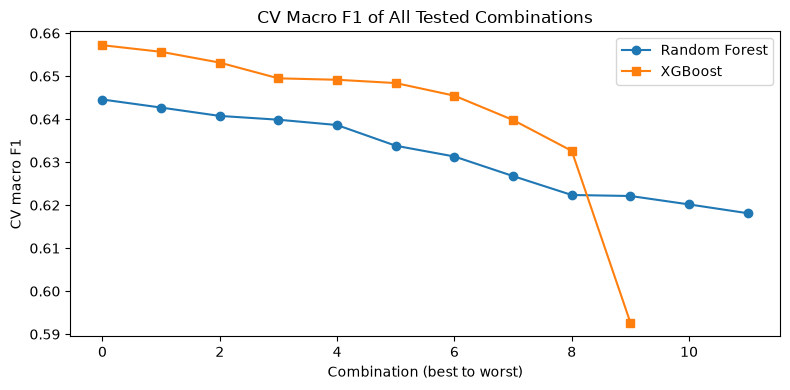


         Model  Default CV F1  Tuned CV F1                                                                                                                                                      Selected parameters
Random Forest         0.6360       0.6446                       {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': None}
      XGBoost         0.6354       0.6572 {'model__subsample': 0.85, 'model__n_estimators': 200, 'model__min_child_weight': 3, 'model__max_depth': 4, 'model__learning_rate': 0.2, 'model__colsample_bytree': 0.8}
Search time (s): RF=68, XGBoost=187
Final training (refit) time (s): RF=13.5, XGBoost=19.1


In [14]:
rf_pipe = Pipeline([('features', make_features(USE_META)), ('scaler', MaxAbsScaler()),
                    ('model', RandomForestClassifier(class_weight='balanced', random_state=SEED))])
rf_space = {'model__n_estimators': [100, 200, 300], 'model__max_depth': [None, 30, 60],
            'model__min_samples_split': [2, 5, 10], 'model__min_samples_leaf': [1, 2, 4],
            'model__max_features': ['sqrt', 'log2']}
rf_search = RandomizedSearchCV(rf_pipe, rf_space, n_iter=12, cv=skf, scoring='f1_macro', random_state=SEED, n_jobs=-1)
t0 = time.time(); rf_search.fit(X_train, y_train); rf_search_time = time.time() - t0

xgb_pipe = Pipeline([('features', make_features(USE_META)), ('scaler', MaxAbsScaler()),
                     ('model', XGBClassifier(objective='multi:softprob', tree_method='hist', random_state=SEED))])
xgb_space = {'model__n_estimators': [100, 150, 200], 'model__max_depth': [3, 4, 6],
             'model__learning_rate': [0.05, 0.1, 0.2], 'model__subsample': [0.7, 0.85, 1.0],
             'model__colsample_bytree': [0.5, 0.8], 'model__min_child_weight': [1, 3, 5]}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=10, cv=skf, scoring='f1_macro', random_state=SEED, n_jobs=-1)
t0 = time.time(); xgb_search.fit(X_train, y_train, model__sample_weight=sw_train)
xgb_search_time = time.time() - t0

tuning_tables = {}
for name, search in [('Random Forest', rf_search), ('XGBoost', xgb_search)]:
    t = pd.DataFrame(search.cv_results_['params'])
    t.columns = [c.replace('model__', '') for c in t.columns]
    t['CV Macro F1'] = search.cv_results_['mean_test_score'].round(4)
    t['Std'] = search.cv_results_['std_test_score'].round(4)
    t['Rank'] = search.cv_results_['rank_test_score']
    tuning_tables[name] = t.sort_values('Rank')
    print(f"\n===== {name}: all tested combinations =====\n", tuning_tables[name].to_string(index=False))
    print("Selected parameters:", search.best_params_)

plt.figure(figsize=(8, 4))
plt.plot(sorted(rf_search.cv_results_['mean_test_score'], reverse=True), marker='o', label='Random Forest')
plt.plot(sorted(xgb_search.cv_results_['mean_test_score'], reverse=True), marker='s', label='XGBoost')
plt.title("CV Macro F1 of All Tested Combinations"); plt.xlabel("Combination (best to worst)"); plt.ylabel("CV macro F1")
plt.legend(); save_show('tuning_candidates')

base = lambda m: ab_table[(ab_table['Model'] == m) & (ab_table['Features'].str.startswith('A'))]['CV Macro F1'].values[0]
tuning_table = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Default CV F1': [base('Random Forest'), base('XGBoost')],
    'Tuned CV F1': [round(rf_search.best_score_, 4), round(xgb_search.best_score_, 4)],
    'Selected parameters': [str(rf_search.best_params_), str(xgb_search.best_params_)]})
print("\n", tuning_table.to_string(index=False))

best_rf, best_xgb = rf_search.best_estimator_, xgb_search.best_estimator_
rf_time, xgb_time = rf_search.refit_time_, xgb_search.refit_time_
print(f"Search time (s): RF={rf_search_time:.0f}, XGBoost={xgb_search_time:.0f}")
print(f"Final training (refit) time (s): RF={rf_time:.1f}, XGBoost={xgb_time:.1f}")

In [15]:
preds = {'Random Forest': best_rf.predict(X_test), 'XGBoost': best_xgb.predict(X_test)}
times = {'Random Forest': rf_time, 'XGBoost': xgb_time}
rows = []
for name, p in preds.items():
    print(f"\n===== {name} =====\n", classification_report(y_test, p, target_names=le.classes_, digits=3))
    rows.append([name, accuracy_score(y_test, p), precision_score(y_test, p, average='macro'),
                 recall_score(y_test, p, average='macro'), f1_score(y_test, p, average='macro'),
                 f1_score(y_test, p, average='weighted'), times[name]])
comparison = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Macro Precision', 'Macro Recall',
                                         'Macro F1', 'Weighted F1', 'Training Time (s)']).round(4)
print("Comparison table:\n", comparison.to_string(index=False))


===== Random Forest =====
               precision    recall  f1-score   support

    negative      0.587     0.604     0.596       273
     neutral      0.554     0.588     0.571       580
    positive      0.853     0.824     0.838      1255

    accuracy                          0.731      2108
   macro avg      0.665     0.672     0.668      2108
weighted avg      0.737     0.731     0.733      2108


===== XGBoost =====
               precision    recall  f1-score   support

    negative      0.605     0.663     0.633       273
     neutral      0.592     0.617     0.604       580
    positive      0.876     0.841     0.858      1255

    accuracy                          0.756      2108
   macro avg      0.691     0.707     0.698      2108
weighted avg      0.763     0.756     0.759      2108

Comparison table:
         Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1  Training Time (s)
Random Forest    0.7306           0.6649        0.6721    0.6682       0

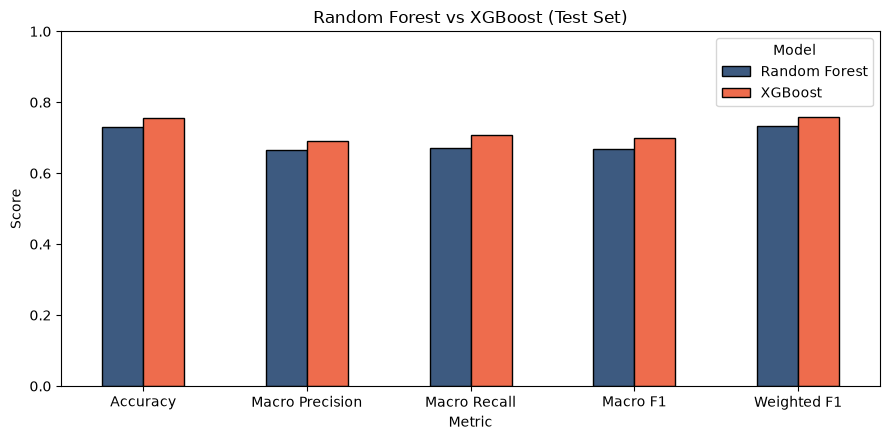

In [16]:
metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Weighted F1']
comparison.set_index('Model')[metrics].T.plot(kind='bar', figsize=(9, 4.5), color=['#3d5a80', '#ee6c4d'], edgecolor='black')
plt.title("Random Forest vs XGBoost (Test Set)"); plt.xlabel("Metric"); plt.ylabel("Score")
plt.ylim(0, 1); plt.xticks(rotation=0); plt.legend(title='Model')
save_show('metric_comparison')

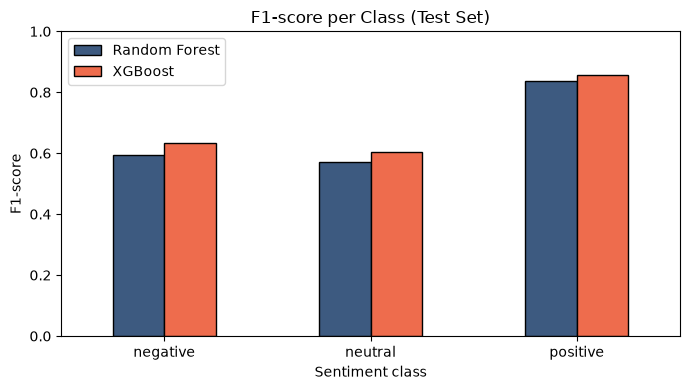

In [17]:
f1_cls = {n: f1_score(y_test, p, average=None) for n, p in preds.items()}
pd.DataFrame(f1_cls, index=le.classes_).plot(kind='bar', figsize=(7, 4), color=['#3d5a80', '#ee6c4d'], edgecolor='black')
plt.title("F1-score per Class (Test Set)"); plt.xlabel("Sentiment class"); plt.ylabel("F1-score")
plt.ylim(0, 1); plt.xticks(rotation=0)
save_show('f1_per_class')

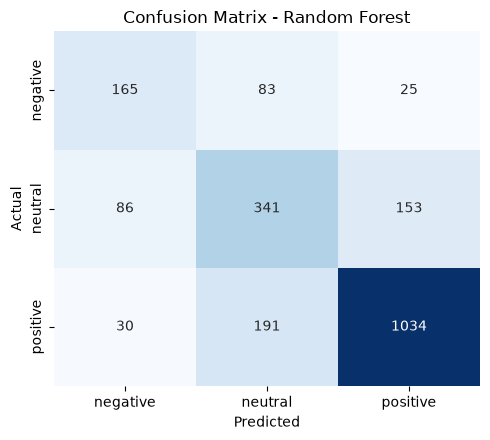

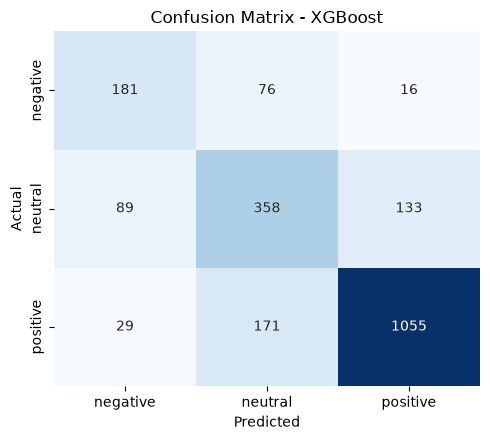

In [18]:
for name, p in preds.items():
    plt.figure(figsize=(5, 4.5))
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title("Confusion Matrix - " + name); plt.xlabel("Predicted"); plt.ylabel("Actual")
    save_show('confusion_' + name.lower().replace(' ', '_'))

In [19]:
print("\nBest model by macro F1:", comparison.loc[comparison['Macro F1'].idxmax(), 'Model'])
for i, c in enumerate(le.classes_):
    r, x = f1_cls['Random Forest'][i], f1_cls['XGBoost'][i]
    print(f"Class {c:8s}: RF F1={r:.3f}, XGB F1={x:.3f} -> better: {'Random Forest' if r > x else 'XGBoost'}")
print("Negative-class recall: RF =", round(recall_score(y_test, preds['Random Forest'], average=None)[0], 3),
      "| XGB =", round(recall_score(y_test, preds['XGBoost'], average=None)[0], 3))
print("Training time ratio (XGBoost / RF):", round(xgb_time / rf_time, 1))


Best model by macro F1: XGBoost
Class negative: RF F1=0.596, XGB F1=0.633 -> better: XGBoost
Class neutral : RF F1=0.571, XGB F1=0.604 -> better: XGBoost
Class positive: RF F1=0.838, XGB F1=0.858 -> better: XGBoost
Negative-class recall: RF = 0.604 | XGB = 0.663
Training time ratio (XGBoost / RF): 1.4


In [20]:
for name, model in [('Random Forest', best_rf), ('XGBoost', best_xgb)]:
    tr = f1_score(y_train, model.predict(X_train), average='macro')
    te = f1_score(y_test, preds[name], average='macro')
    cm = confusion_matrix(y_test, preds[name])
    print(f"{name}: train macro F1={tr:.3f}, test={te:.3f}, gap={tr - te:.3f} | "
          f"negative<->positive mistakes: {cm[0, 2] + cm[2, 0]} of {len(y_test)}")
print("Limitations: labels from star ratings, neutral class ambiguous, two cities, English only, "
      "one train/test split, small search, unverified data source.")

Random Forest: train macro F1=0.933, test=0.668, gap=0.265 | negative<->positive mistakes: 55 of 2108
XGBoost: train macro F1=0.908, test=0.698, gap=0.209 | negative<->positive mistakes: 45 of 2108
Limitations: labels from star ratings, neutral class ambiguous, two cities, English only, one train/test split, small search, unverified data source.


In [21]:
joblib.dump(best_xgb, 'models/xgboost_pipeline.joblib')
joblib.dump(best_rf, 'models/random_forest_pipeline.joblib')
joblib.dump(le, 'models/label_encoder.joblib')
comparison.to_csv('results/model_comparison.csv', index=False)
ab_table.to_csv('results/feature_experiment.csv', index=False)
for n, t in tuning_tables.items():
    t.to_csv(f"results/tuning_{n.lower().replace(' ', '_')}.csv", index=False)

def predict_sentiment(review_text, city='Kathmandu', domain='Attraction'):
    # city/domain are accepted for interface consistency; the text-only pipeline (USE_META=False) ignores them.
    model = joblib.load('models/xgboost_pipeline.joblib')
    encoder = joblib.load('models/label_encoder.joblib')
    row = pd.DataFrame({'review_clean': [clean_text(review_text)], 'city': [city], 'domain': [domain]})
    probs = model.predict_proba(row)[0]
    return encoder.classes_[probs.argmax()], probs.round(2)

for text, city, domain in [
    ("The temple was beautiful and the staff were really friendly. Highly recommend!", 'Kathmandu', 'Attraction'),
    ("The room was dirty, the staff were rude and the hot water didn't work.", 'Pokhara', 'Hotel'),
    ("The hotel was okay. Location is fine but nothing special.", 'Pokhara', 'Hotel')]:
    print(text[:50], '->', *predict_sentiment(text, city, domain))

The temple was beautiful and the staff were really -> positive [0.06 0.06 0.88]
The room was dirty, the staff were rude and the ho -> negative [0.89 0.09 0.01]
The hotel was okay. Location is fine but nothing s -> neutral [0.18 0.78 0.04]
